In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from scipy.stats import shapiro, norm, chi2
from statsmodels.stats.diagnostic import het_breuschpagan

# Загружаем исходный Excel-файл
df = pd.read_excel(
    r"D:\ЛАБА1 (3).xlsx",
    sheet_name="dataset",
    na_values=["?"]
)

# Преобразуем используемые числовые признаки в числовой формат
numeric_columns = ["price", "horsepower", "engine-size"]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Выбираем признаки для регрессионного анализа
selected_columns = [
    "price",
    "horsepower",
    "engine-size",
    "body-style"
]

data = df[selected_columns].dropna().copy()

# Преобразуем тип кузова в категориальную переменную
data["body-style"] = data["body-style"].astype("category")

print("Количество наблюдений:", len(data))

print("\nПервые строки:")
display(data.head())

print("\nРаспределение типов кузова:")
print(data["body-style"].value_counts())

Количество наблюдений: 199

Первые строки:


,price,horsepower,engine-size,body-style
0,13495.0,111.0,130,convertible
1,16500.0,111.0,130,convertible
2,16500.0,154.0,152,hatchback
3,13950.0,102.0,109,sedan
4,17450.0,115.0,136,sedan



Распределение типов кузова:
body-style
sedan          94
hatchback      67
wagon          24
hardtop         8
convertible     6
Name: count, dtype: int64


In [2]:
# Разделяем зависимую и независимые переменные
y = data["price"]

data["body-style"] = pd.Categorical(
    data["body-style"],
    categories=[
        "sedan",
        "convertible",
        "hardtop",
        "hatchback",
        "wagon"
    ]
)

X = data[
    ["horsepower", "engine-size", "body-style"]
]

# Создаём фиктивные переменные для body-style
X = pd.get_dummies(
    X,
    columns=["body-style"],
    drop_first=True,
    dtype=float
)

# Добавляем свободный коэффициент
X = sm.add_constant(X)


# Строим линейную регрессию методом наименьших квадратов
model_linear = sm.OLS(y, X).fit()

# Выводим подробную статистику
print(model_linear.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.807
Model:                            OLS   Adj. R-squared:                  0.800
Method:                 Least Squares   F-statistic:                     133.4
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.01e-65
Time:                        19:21:40   Log-Likelihood:                -1906.3
No. Observations:                 199   AIC:                             3827.
Df Residuals:                     192   BIC:                             3850.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                  -6974

In [3]:
# Коэффициенты регрессии
print("Коэффициенты регрессии:")
print(model_linear.params)

# Коэффициент детерминации
print("\nR²:", model_linear.rsquared)

# Скорректированный коэффициент детерминации
print("Adjusted R²:", model_linear.rsquared_adj)

# F-статистика
print("\nF-статистика:", model_linear.fvalue)

# p-value модели
print("p-value модели:", model_linear.f_pvalue)

# Таблица значимости отдельных коэффициентов
print("\nЗначимость коэффициентов:")
print(model_linear.pvalues)

Коэффициенты регрессии:
const                    -6974.850080
horsepower                  65.601228
engine-size                111.052276
body-style_convertible    2774.139014
body-style_hardtop         278.611751
body-style_hatchback     -1974.996214
body-style_wagon          -652.459377
dtype: float64

R²: 0.8065338246020293
Adjusted R²: 0.8004880066208426

F-статистика: 133.40359023573097
p-value модели: 1.01495156270045e-65

Значимость коэффициентов:
const                     2.189701e-12
horsepower                1.649150e-07
engine-size               4.191048e-19
body-style_convertible    6.832282e-02
body-style_hardtop        8.361222e-01
body-style_hatchback      1.010471e-03
body-style_wagon          4.253807e-01
dtype: float64


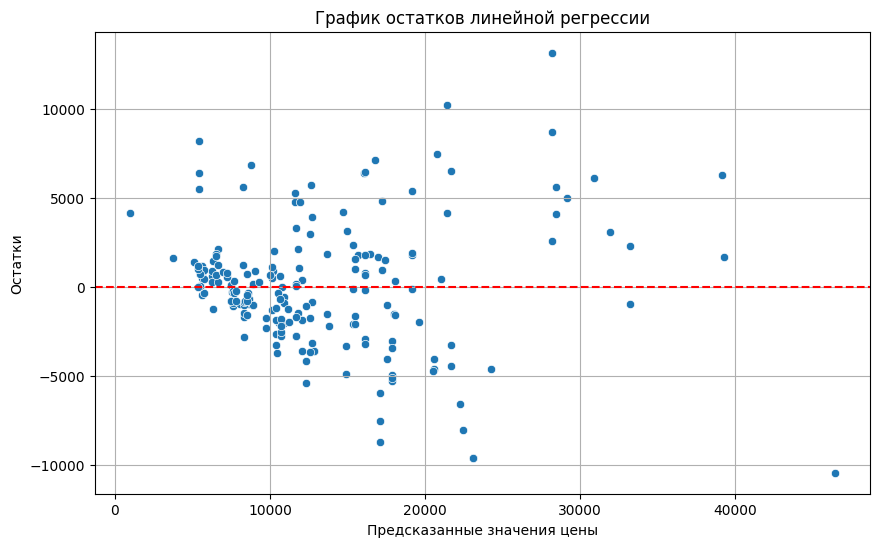

In [4]:
# Получаем предсказанные значения и остатки
fitted = model_linear.fittedvalues
residuals = model_linear.resid

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=fitted,
    y=residuals
)

# Нулевая линия
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("График остатков линейной регрессии")
plt.xlabel("Предсказанные значения цены")
plt.ylabel("Остатки")

plt.grid(True)
plt.show()

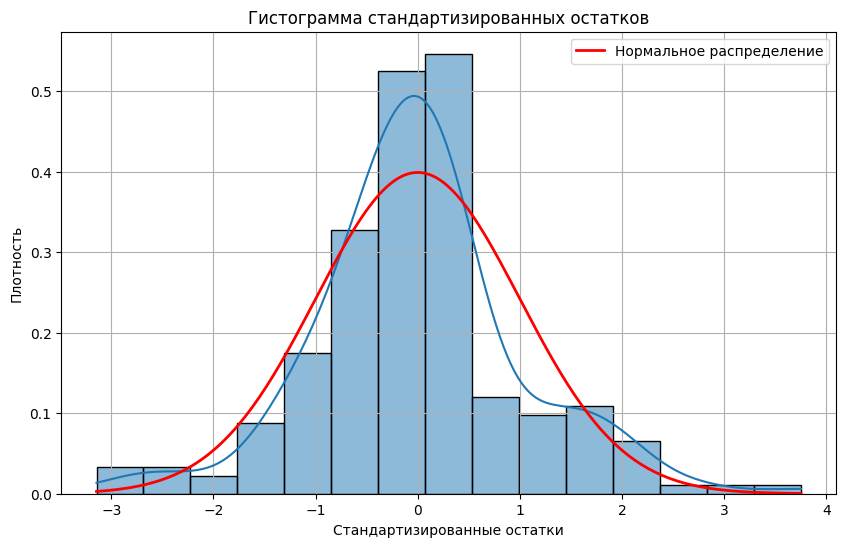

p-value: 0.00015996688019273596


In [5]:
# Получаем внутренне стандартизированные остатки
standardized_residuals = (
    model_linear
    .get_influence()
    .resid_studentized_internal
)

plt.figure(figsize=(10, 6))

# Гистограмма
sns.histplot(
    standardized_residuals,
    bins=15,
    stat="density",
    kde=True
)

# Теоретическая нормальная кривая
x = np.linspace(
    min(standardized_residuals),
    max(standardized_residuals),
    200
)

plt.plot(
    x,
    norm.pdf(x),
    color="red",
    linewidth=2,
    label="Нормальное распределение"
)

plt.title("Гистограмма стандартизированных остатков")
plt.xlabel("Стандартизированные остатки")
plt.ylabel("Плотность")

plt.legend()
plt.grid(True)
plt.show()

shapiro_result = shapiro(standardized_residuals)

print("p-value:", shapiro_result.pvalue)

In [6]:
# Используем ту же зависимую переменную, что и в линейной модели
y_poisson = data["price"]

# Используем те же независимые переменные
X_poisson = X.copy()

print("Количество наблюдений:", len(y_poisson))

print("Зависимая переменная: price")
print("Независимые переменные:")
print(X_poisson.columns.tolist())

Количество наблюдений: 199
Зависимая переменная: price
Независимые переменные:
['const', 'horsepower', 'engine-size', 'body-style_convertible', 'body-style_hardtop', 'body-style_hatchback', 'body-style_wagon']


In [7]:
# Строим пуассоновскую регрессию
model_poisson = sm.GLM(
    y_poisson,
    X_poisson,
    family=sm.families.Poisson()
).fit(scale="X2")   

# Выводим результаты
print(model_poisson.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  price   No. Observations:                  199
Model:                            GLM   Df Residuals:                      192
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          894.93
Method:                          IRLS   Log-Likelihood:                -95.568
Date:                Thu, 05 Nov 2026   Deviance:                   1.6883e+05
Time:                        19:21:41   Pearson chi2:                 1.72e+05
No. Iterations:                     7   Pseudo R-squ. (CS):             0.9696
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      8

In [8]:
dispersion = (
    model_poisson.pearson_chi2 /
    model_poisson.df_resid
)

print("Коэффициент дисперсии:", dispersion)

if dispersion > 1.5:
    print("Обнаруживается возможная сверхдисперсия")
elif dispersion < 0.8:
    print("Обнаруживается возможная недодисперсия")
else:
    print("Дисперсия близка к ожидаемой")

Коэффициент дисперсии: 894.931886811476
Обнаруживается возможная сверхдисперсия


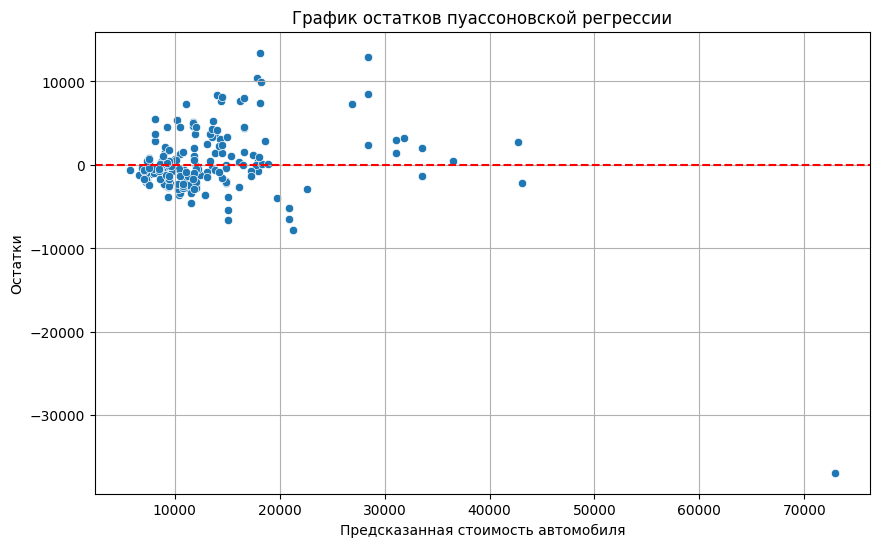

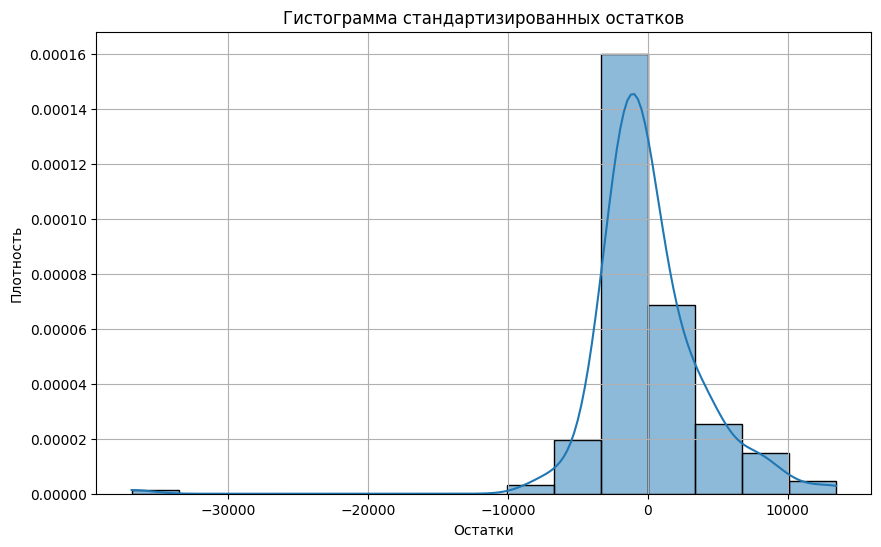

In [9]:
# Предсказанные значения цены
poisson_fitted = model_poisson.fittedvalues

# Стандартизированные остатки Пирсона
poisson_residuals = y_poisson - poisson_fitted



# График остатков
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=poisson_fitted,
    y=poisson_residuals
)

plt.axhline(0, color="red", linestyle="--")

plt.title("График остатков пуассоновской регрессии")
plt.xlabel("Предсказанная стоимость автомобиля")
plt.ylabel("Остатки")

plt.grid(True)
plt.show()

# Гистограмма
plt.figure(figsize=(10, 6))

sns.histplot(
    poisson_residuals,
    bins=15,
    kde=True,
    stat="density"
)

plt.title("Гистограмма стандартизированных остатков")
plt.xlabel("Остатки")
plt.ylabel("Плотность")

plt.grid(True)
plt.show()

In [10]:
# Копируем матрицу признаков предыдущей линейной модели
X_nonlinear = X.copy()

# Добавляем нелинейное преобразование объёма двигателя
X_nonlinear["log_engine_size"] = np.log(
    data["engine-size"]
)

print("Матрица признаков нелинейной модели:")
display(X_nonlinear.head())

Матрица признаков нелинейной модели:


,const,horsepower,engine-size,body-style_convertible,body-style_hardtop,body-style_hatchback,body-style_wagon,log_engine_size
0,1.0,111.0,130,1.0,0.0,0.0,0.0,4.867534
1,1.0,111.0,130,1.0,0.0,0.0,0.0,4.867534
2,1.0,154.0,152,0.0,0.0,1.0,0.0,5.023881
3,1.0,102.0,109,0.0,0.0,0.0,0.0,4.691348
4,1.0,115.0,136,0.0,0.0,0.0,0.0,4.912655


In [11]:
# Строим нелинейную модель методом наименьших квадратов
model_nonlinear = sm.OLS(
    y,
    X_nonlinear
).fit()

# Вывод результатов
print(model_nonlinear.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     119.3
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.24e-66
Time:                        19:21:42   Log-Likelihood:                -1902.5
No. Observations:                 199   AIC:                             3821.
Df Residuals:                     191   BIC:                             3847.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   3.84

In [12]:
print("Коэффициенты нелинейной модели:")
print(model_nonlinear.params)

print("\nR²:", model_nonlinear.rsquared)

print("Adjusted R²:", model_nonlinear.rsquared_adj)

print("F-статистика:", model_nonlinear.fvalue)

print("p-value:", model_nonlinear.f_pvalue)

print("\nЗначимость коэффициентов:")
print(model_nonlinear.pvalues)

Коэффициенты нелинейной модели:
const                     38457.863128
horsepower                   72.334220
engine-size                 181.107423
body-style_convertible     2932.089362
body-style_hardtop          187.620225
body-style_hatchback      -2251.783555
body-style_wagon           -520.557345
log_engine_size          -11446.677375
dtype: float64

R²: 0.8137987415127165
Adjusted R²: 0.8069746116205123
F-статистика: 119.25311422374898
p-value: 3.238399455568806e-66

Значимость коэффициентов:
const                     2.211026e-02
horsepower                1.162643e-08
engine-size               7.221229e-10
body-style_convertible    5.047287e-02
body-style_hardtop        8.874128e-01
body-style_hatchback      1.853509e-04
body-style_wagon          5.185491e-01
log_engine_size           6.928579e-03
dtype: float64


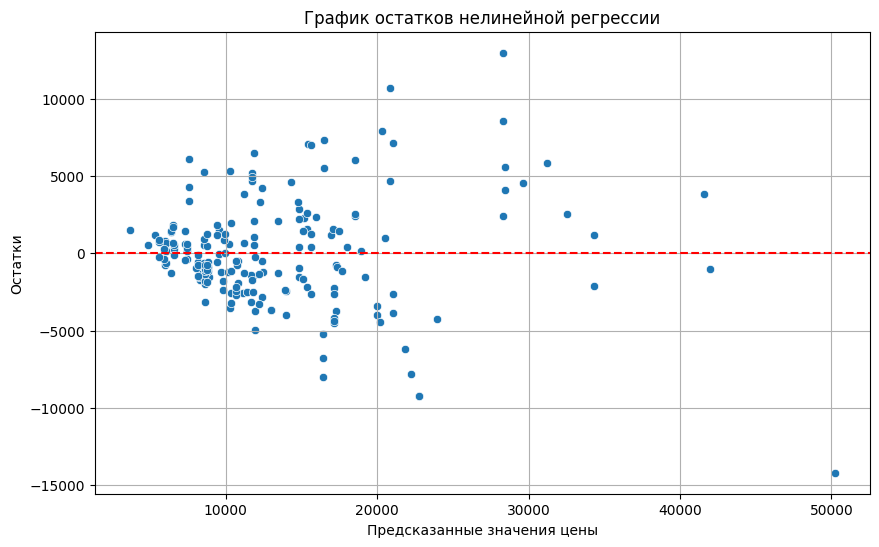

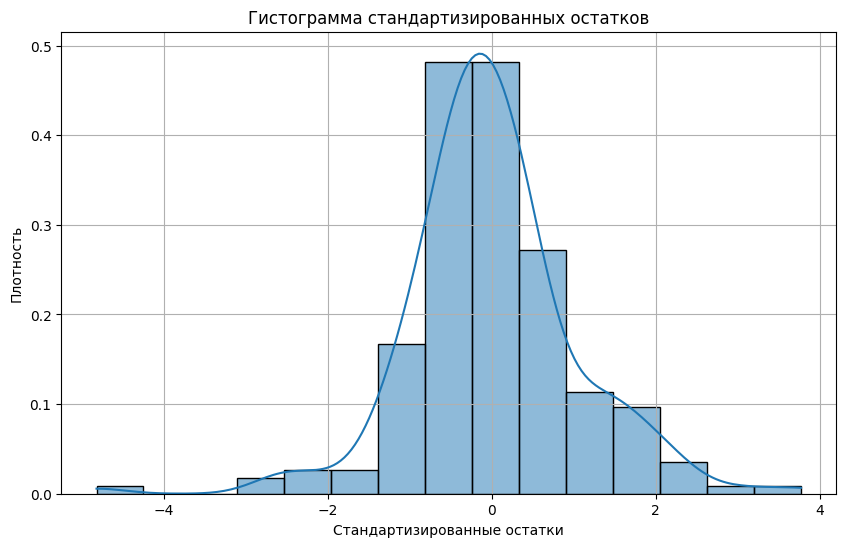

In [13]:
# Предсказанные значения
fitted_nonlinear = model_nonlinear.fittedvalues

# Остатки
residuals_nonlinear = model_nonlinear.resid

# Стандартизированные остатки
standardized_nonlinear = (
    model_nonlinear
    .get_influence()
    .resid_studentized_internal
)

# График остатков
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=fitted_nonlinear,
    y=residuals_nonlinear
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.title("График остатков нелинейной регрессии")
plt.xlabel("Предсказанные значения цены")
plt.ylabel("Остатки")

plt.grid(True)
plt.show()

# Гистограмма стандартизированных остатков
plt.figure(figsize=(10, 6))

sns.histplot(
    standardized_nonlinear,
    bins=15,
    kde=True,
    stat="density"
)

plt.title("Гистограмма стандартизированных остатков")
plt.xlabel("Стандартизированные остатки")
plt.ylabel("Плотность")

plt.grid(True)
plt.show()